# Figure S6 - Intramolecular scaling maps for wild-type DDX4 and phase-separation-deficient variants

**What the figure shows.** Four maps, one per sequence, each summarising every pairwise distance in the chain. The colour at position $(i, j)$ is the mean distance between residues $i$ and $j$, **normalised by the distance between the equivalent pair in a serine-proline dipeptide repeat** of the same length. That normalisation is what makes the map readable: an SP repeat is an expanded, uniformly interacting IDR with no sequence-specific structure, so it is a null model for "a chain of this length with nothing interesting going on".

* Values near the top of the scale mean the pair sits at roughly the distance the null model predicts - no specific attraction.
* Values well below it mean that pair is systematically closer together than chain connectivity alone would put them, which is the signature of a real intramolecular interaction.

**(A) Wild-type.** Large regions of the map are strongly compressed relative to the null model, and the effect is not local - it spans the sequence. The region between residues 80 and 140 is especially prominent, driven by a high local density of arginine-aromatic contacts. These are the same subregions predicted computationally and measured experimentally to be critical for condensate formation.

**(B, C, D) The variants.** Each removes one class of interaction: **24RtoK** replaces arginines with lysines (disrupting cation-pi), **14FtoA** replaces phenylalanines with alanines (disrupting both cation-pi and pi-pi), and **37EDtoA** replaces the negatively charged residues with alanine (disrupting electrostatics). All three show a marked, global loss of long-range contacts - the maps become uniformly pale. Since all three variants are also phase-separation deficient, this ties the intramolecular interactions seen here directly to the intermolecular interactions that drive condensation.

Figure S7 shows the consequence for overall chain dimensions: losing these contacts makes every variant expand.

**A note on the 24RtoK construct.** That variant uses the DDX4<sup>[1-236]</sup> construct, to match previously reported experimental work, so it is 236 residues rather than 245. It is therefore normalised against a 236-residue SP repeat - the null model has to be the same length as the sequence it is normalising, or the comparison is meaningless.

**How it is made.** Ensembles were generated with [STARLING](https://github.com/idptools/starling) and the mean distance maps taken directly from the ensemble objects.

## What is in this directory

| path | contents |
|------|----------|
| `figures/` | output; the notebook writes one PDF and PNG per panel |

This figure has no data files of its own. It reads six STARLING ensembles (~1.5 GB together) from the shared `data/` directory at the root of `perets_2025`, which is **not tracked by git** - see [`../data/README.md`](../data/README.md).

## Setup

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

# ---------------------------------------------------------------------------
# Holehouse lab figure defaults (December 2024)
# ---------------------------------------------------------------------------

# export PDF/PS fonts as TrueType so text stays editable in Illustrator/Affinity
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

matplotlib.rcParams['axes.linewidth'] = 0.5
matplotlib.rcParams['lines.linewidth'] = 0.8

matplotlib.rcParams['xtick.major.size'] = 2
matplotlib.rcParams['xtick.minor.size'] = 0.5
matplotlib.rcParams['ytick.major.size'] = 2
matplotlib.rcParams['ytick.minor.size'] = 0.5
matplotlib.rcParams['xtick.major.width'] = 0.375
matplotlib.rcParams['ytick.major.width'] = 0.375
matplotlib.rcParams['xtick.minor.width'] = 0.375
matplotlib.rcParams['ytick.minor.width'] = 0.375
matplotlib.rcParams['xtick.major.pad'] = 1
matplotlib.rcParams['ytick.major.pad'] = 1

matplotlib.rcParams['xtick.labelsize'] = 8
matplotlib.rcParams['ytick.labelsize'] = 8
matplotlib.rcParams['axes.labelsize'] = 10
matplotlib.rcParams['legend.fontsize'] = 8

# The manuscript figures used Arial; the fallbacks let this run anywhere.
matplotlib.rcParams['font.family'] = 'sans-serif'
matplotlib.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']

%matplotlib inline
%config InlineBackend.figure_format = 'retina'

from mpl_toolkits.axes_grid1 import make_axes_locatable

from starling import load_ensemble

In [2]:
import os

DATA_DIR = os.environ.get('PERETS_DATA_DIR', '../data')
STARLING_DIR = os.path.join(DATA_DIR, 'starling')

os.makedirs('figures', exist_ok=True)

# Each variant is paired with the SP-repeat null model of matching length.
# 24RtoK uses the DDX4[1-236] construct, so it needs the 236-residue repeat.
PANELS = [
    ('A', 'DDX4 NTD (wildtype)', 'ddx4_wt.starling',      'sp_repeat_245.starling', 'wildtype'),
    ('B', '24RtoK',              'ddx4_24RtoK.starling',  'sp_repeat_236.starling', '24RtoK'),
    ('C', '14FtoA',              'ddx4_14FtoA.starling',  'sp_repeat_245.starling', '14FtoA'),
    ('D', '37EDtoA',             'ddx4_37EDtoA.starling', 'sp_repeat_245.starling', '37EDtoA'),
]

needed = sorted({f for _, _, seq, ref, _ in PANELS for f in (seq, ref)})
for filename in needed:
    path = os.path.join(STARLING_DIR, filename)
    status = 'found' if os.path.isfile(path) else 'MISSING - see ../data/README.md'
    print(f'{filename:<26} [{status}]')

ddx4_14FtoA.starling       [found]
ddx4_24RtoK.starling       [found]
ddx4_37EDtoA.starling      [found]
ddx4_wt.starling           [found]
sp_repeat_236.starling     [found]
sp_repeat_245.starling     [found]


## Load the ensembles

Six ensembles: the four sequences, plus the two SP-repeat null models. Each `.starling` file stores the ensemble as a stack of inter-residue distance maps, so `distance_maps(return_mean=True)` is just an average over that stack.

In [3]:
ensembles = {}
for filename in needed:
    ensembles[filename] = load_ensemble(os.path.join(STARLING_DIR, filename))

for filename, ensemble in ensembles.items():
    print(f'{filename:<26} {len(ensemble):>5,} conformers, {len(ensemble.sequence)} residues')

ddx4_14FtoA.starling       1,600 conformers, 245 residues
ddx4_24RtoK.starling       1,600 conformers, 236 residues
ddx4_37EDtoA.starling      1,600 conformers, 245 residues
ddx4_wt.starling           1,600 conformers, 245 residues
sp_repeat_236.starling       800 conformers, 236 residues
sp_repeat_245.starling       800 conformers, 245 residues


## Building a scaling map

The scaling map is the elementwise ratio of two mean distance maps. Two details are worth stating explicitly:

* **The diagonal is undefined.** The distance from a residue to itself is zero in both maps, so the ratio is 0/0. Those entries come back as `nan` and are drawn in white by setting the colormap's "bad" colour; they carry no information.
* **The map is transposed before drawing.** This is purely a plotting convention, so residue $i$ runs along the x-axis and $j$ up the y-axis. The matrix is symmetric, so this changes nothing quantitatively.

The colour scale is fixed at 0.60 to 0.80 across all four panels. Holding it fixed is what makes the panels comparable - the loss of long-range contacts in B, C and D is visible precisely because the same colour means the same normalised distance in every panel.

In [4]:
def plot_scaling_map(ensemble, reference_ensemble, title, outfile, vmin=0.60, vmax=0.80):
    """
    Draw an intramolecular scaling map for one sequence.

    The scaling map is the mean inter-residue distance map of `ensemble`
    divided elementwise by that of `reference_ensemble`, which is a
    serine-proline dipeptide repeat of matching length acting as a null model
    for an expanded, uniformly interacting IDR. Values below 1 indicate pairs
    of residues that are closer together than the null model predicts.

    Parameters
    ----------
    ensemble : starling.structure.ensemble.Ensemble
        The ensemble whose scaling map is drawn.

    reference_ensemble : starling.structure.ensemble.Ensemble
        The SP-repeat null model. Must be the same length as `ensemble`.

    title : str
        Title placed above the panel.

    outfile : str
        Path stem (without extension); both a PDF and a PNG are written.

    vmin : float
        Lower limit of the colour scale. Default = 0.60.

    vmax : float
        Upper limit of the colour scale. Default = 0.80.

    Returns
    -------
    numpy.ndarray
        The scaling map that was drawn.
    """

    distance_map = ensemble.distance_maps(return_mean=True)
    reference_map = reference_ensemble.distance_maps(return_mean=True)

    if distance_map.shape != reference_map.shape:
        raise ValueError(f'Shape mismatch: {distance_map.shape} vs {reference_map.shape}. '
                         'The null model must be the same length as the sequence.')

    # the diagonal is 0/0 and comes back as nan; it is drawn in white below
    with np.errstate(divide='ignore', invalid='ignore'):
        scaling_map = distance_map / reference_map

    fig = plt.figure(figsize=(3, 3), dpi=350, facecolor='w', edgecolor='k')

    cmap = matplotlib.colormaps['plasma'].copy()
    cmap.set_bad(color='white')

    max_extent = distance_map.shape[0]

    # transposed purely for plotting convention; the matrix is symmetric
    plt.imshow(scaling_map.transpose(), cmap=cmap, interpolation='bilinear',
               origin='lower', extent=[1, max_extent, 1, max_extent],
               vmin=vmin, vmax=vmax)

    plt.title(title, fontsize=7)
    plt.xlabel('Residue $i$', fontsize=6)
    plt.ylabel('Residue $j$', fontsize=6)

    plt.xticks(np.arange(0, max_extent + 1, 20), fontsize=5)
    plt.yticks(np.arange(0, max_extent + 1, 20), fontsize=5)
    plt.xlim([1, max_extent])
    plt.ylim([1, max_extent])

    ax = plt.gca()
    divider = make_axes_locatable(ax)
    cax = divider.append_axes('right', size='5%', pad=0.05)
    cb = plt.colorbar(cax=cax)
    cb.ax.tick_params(labelsize=4)
    cb.set_label('Normalized distance', fontsize=5)

    plt.tight_layout()
    plt.savefig(f'{outfile}.pdf')
    plt.savefig(f'{outfile}.png', dpi=350)
    plt.show()

    return scaling_map

## The four panels

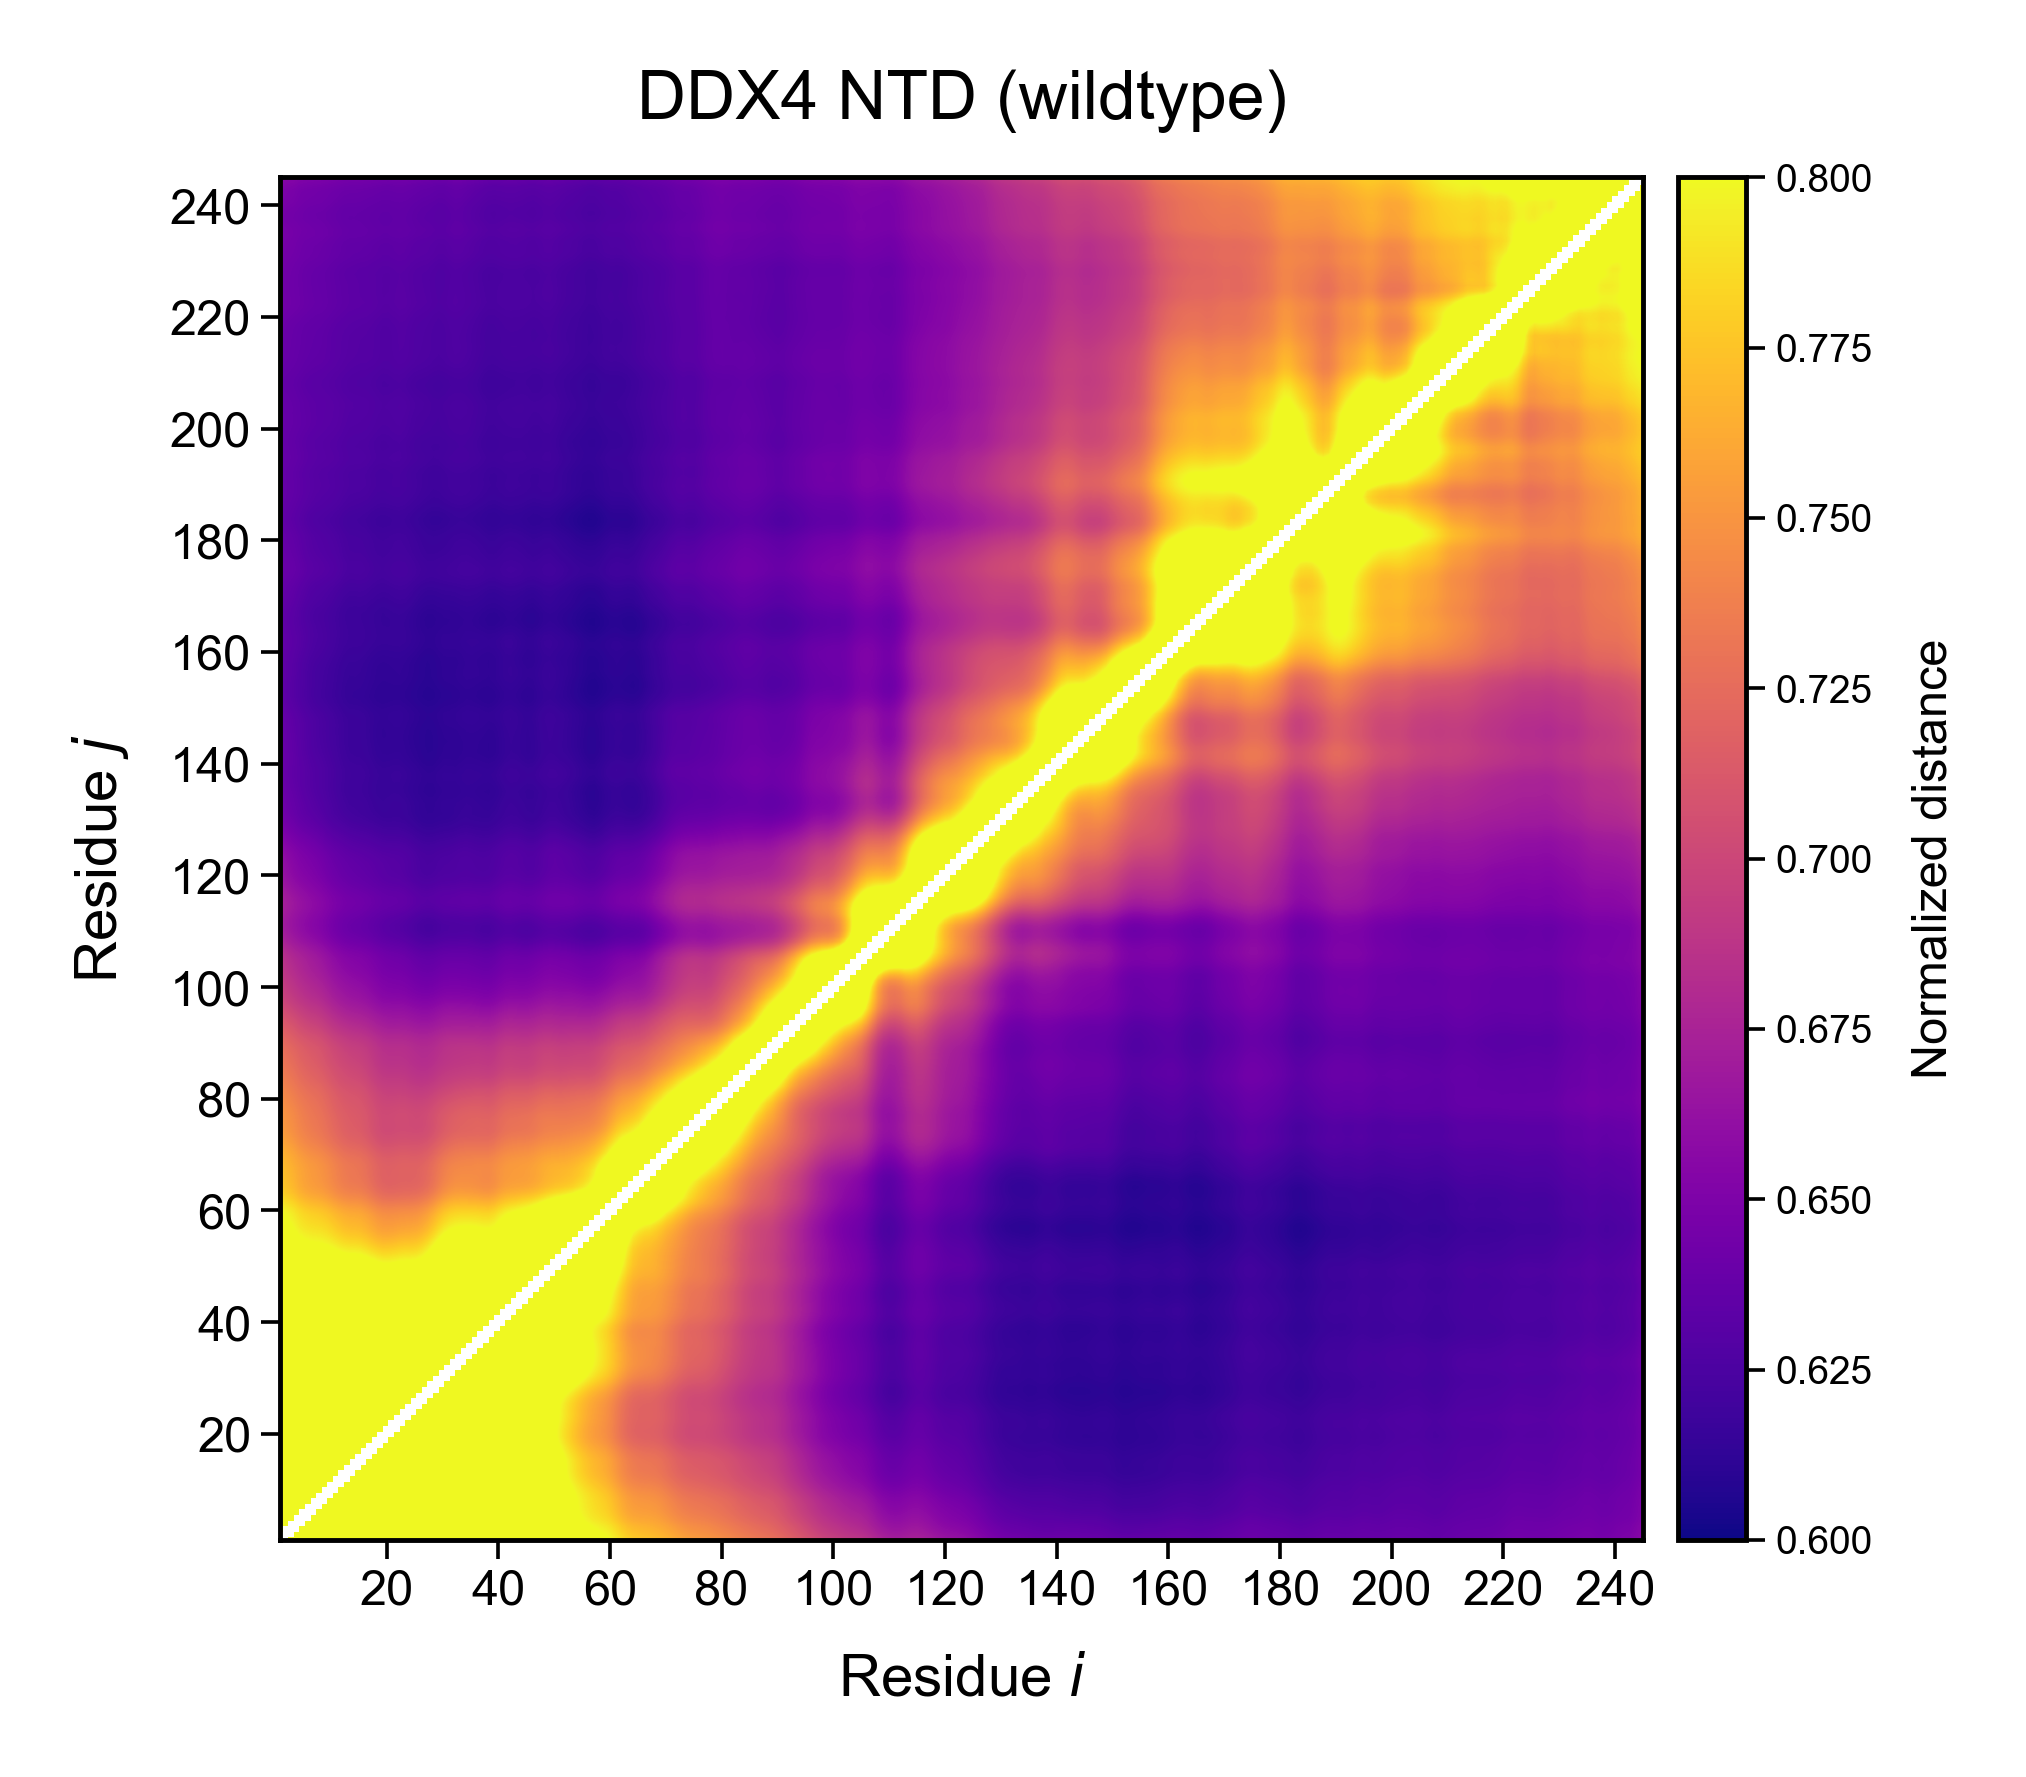

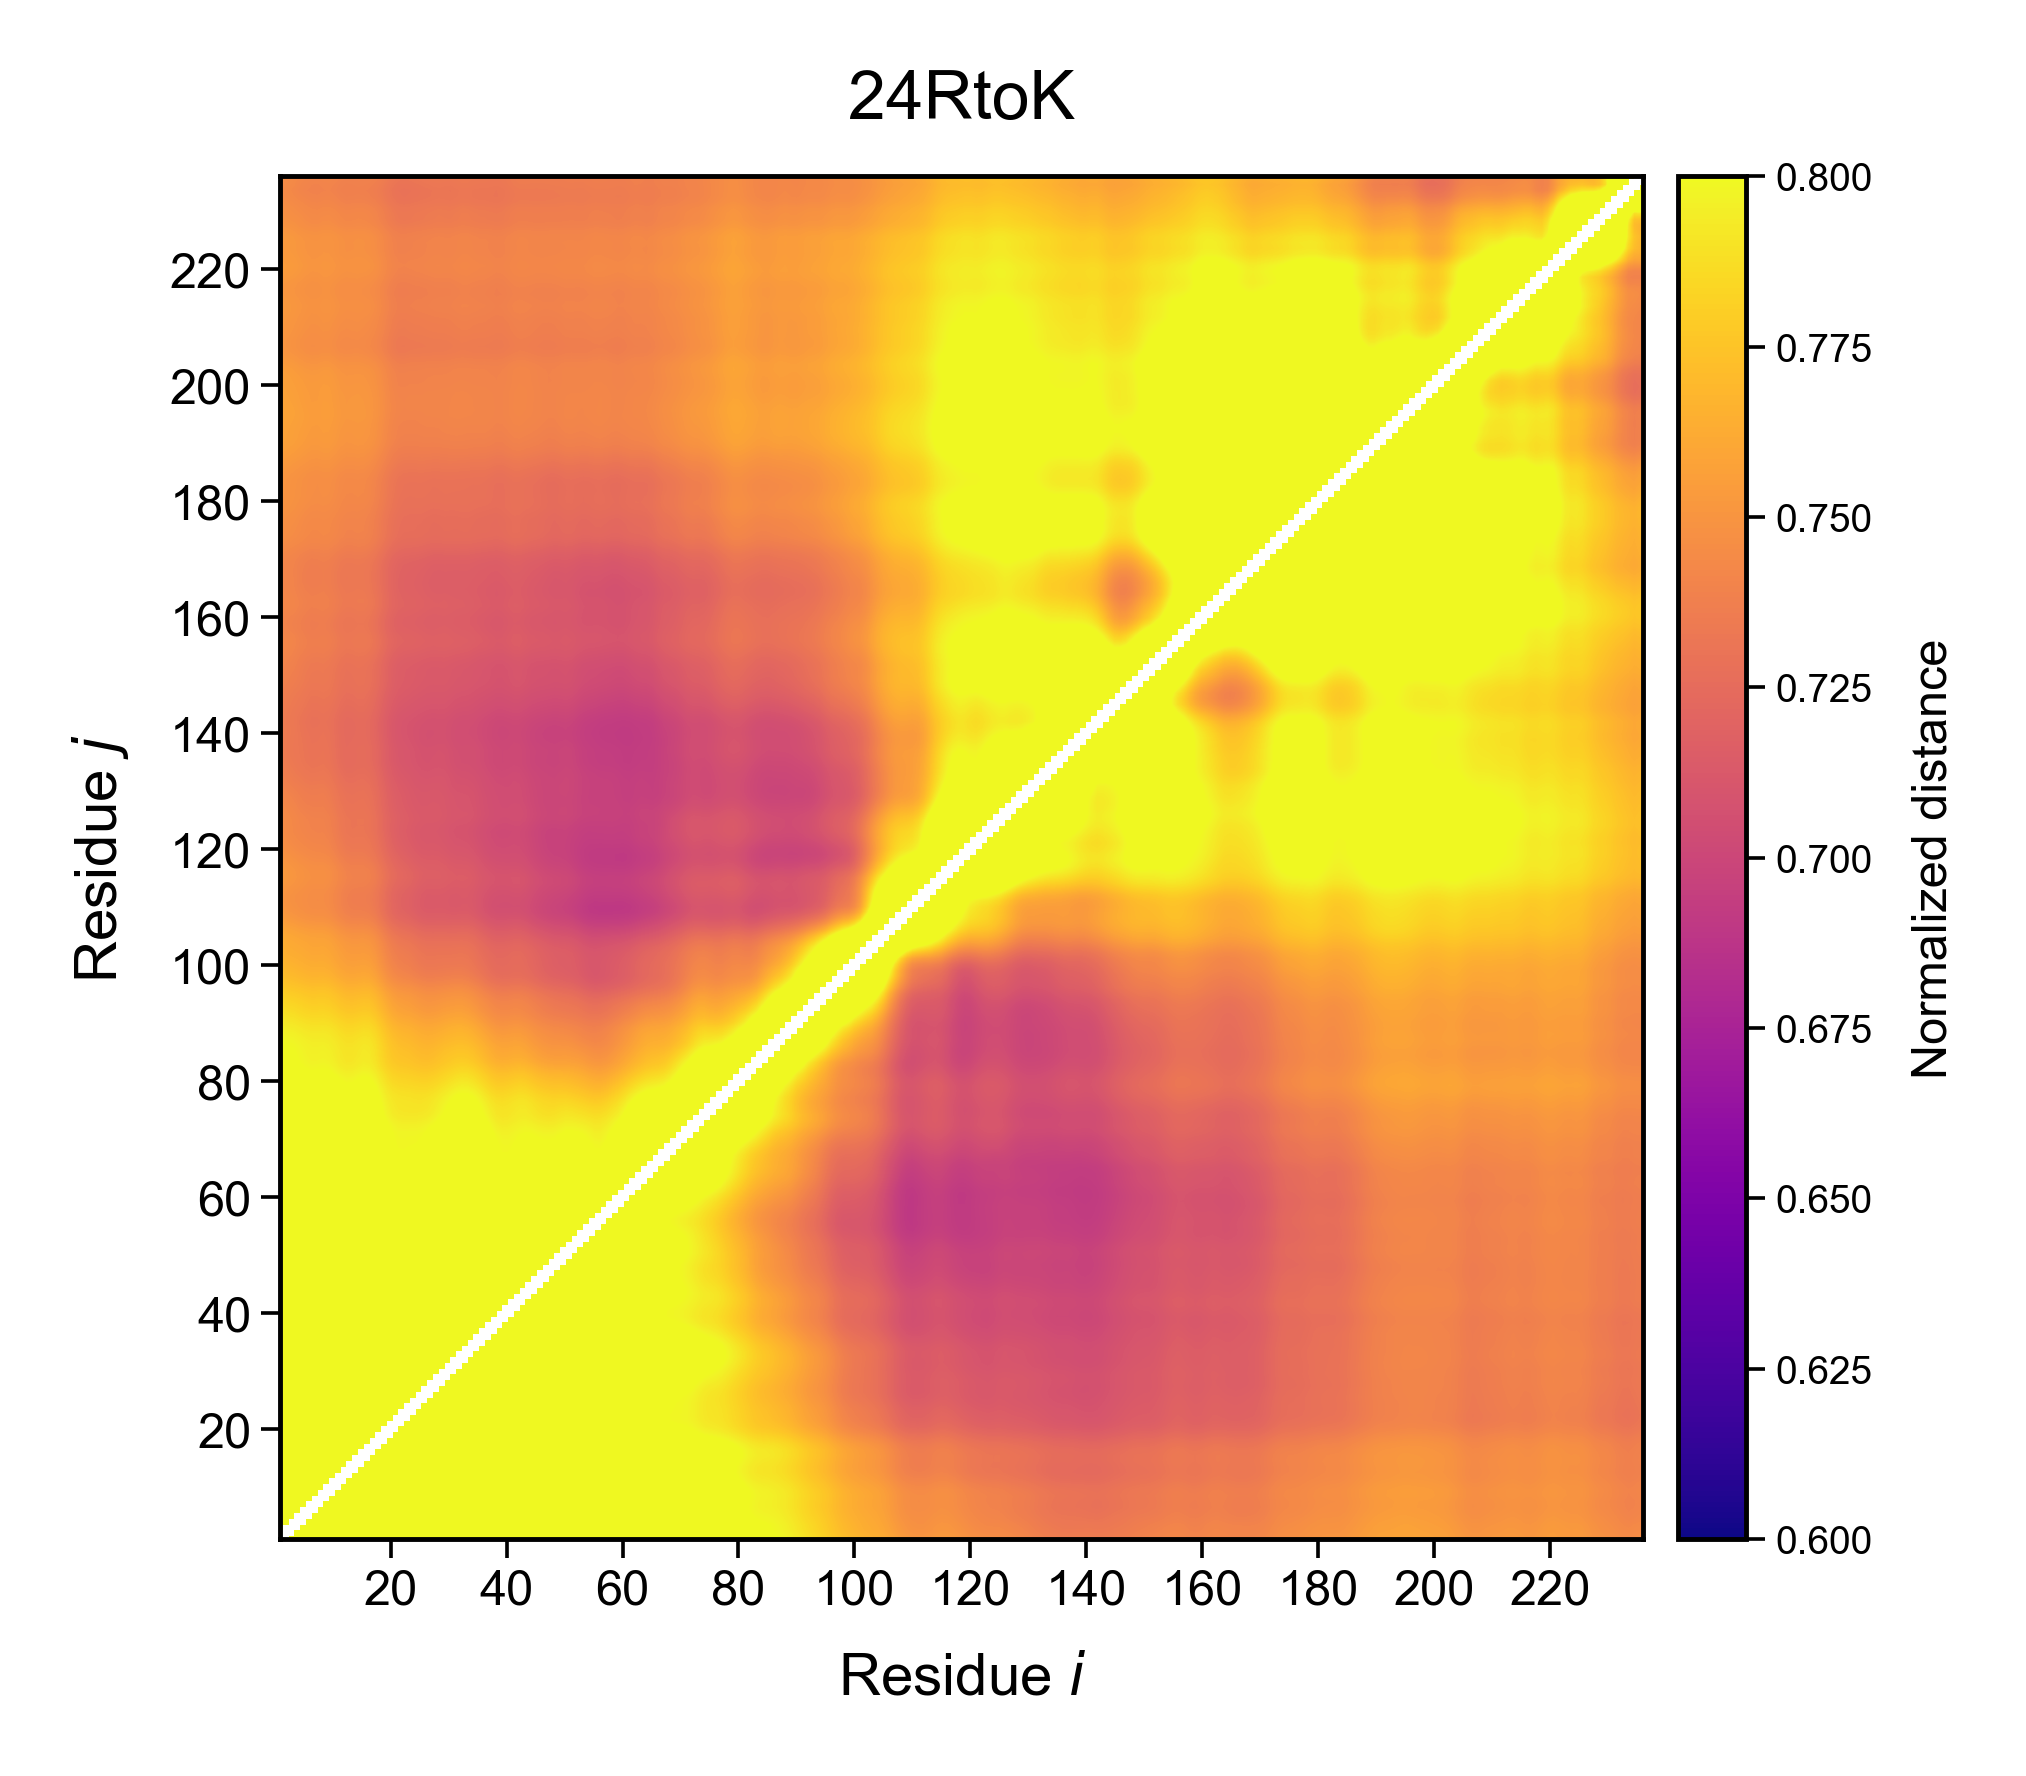

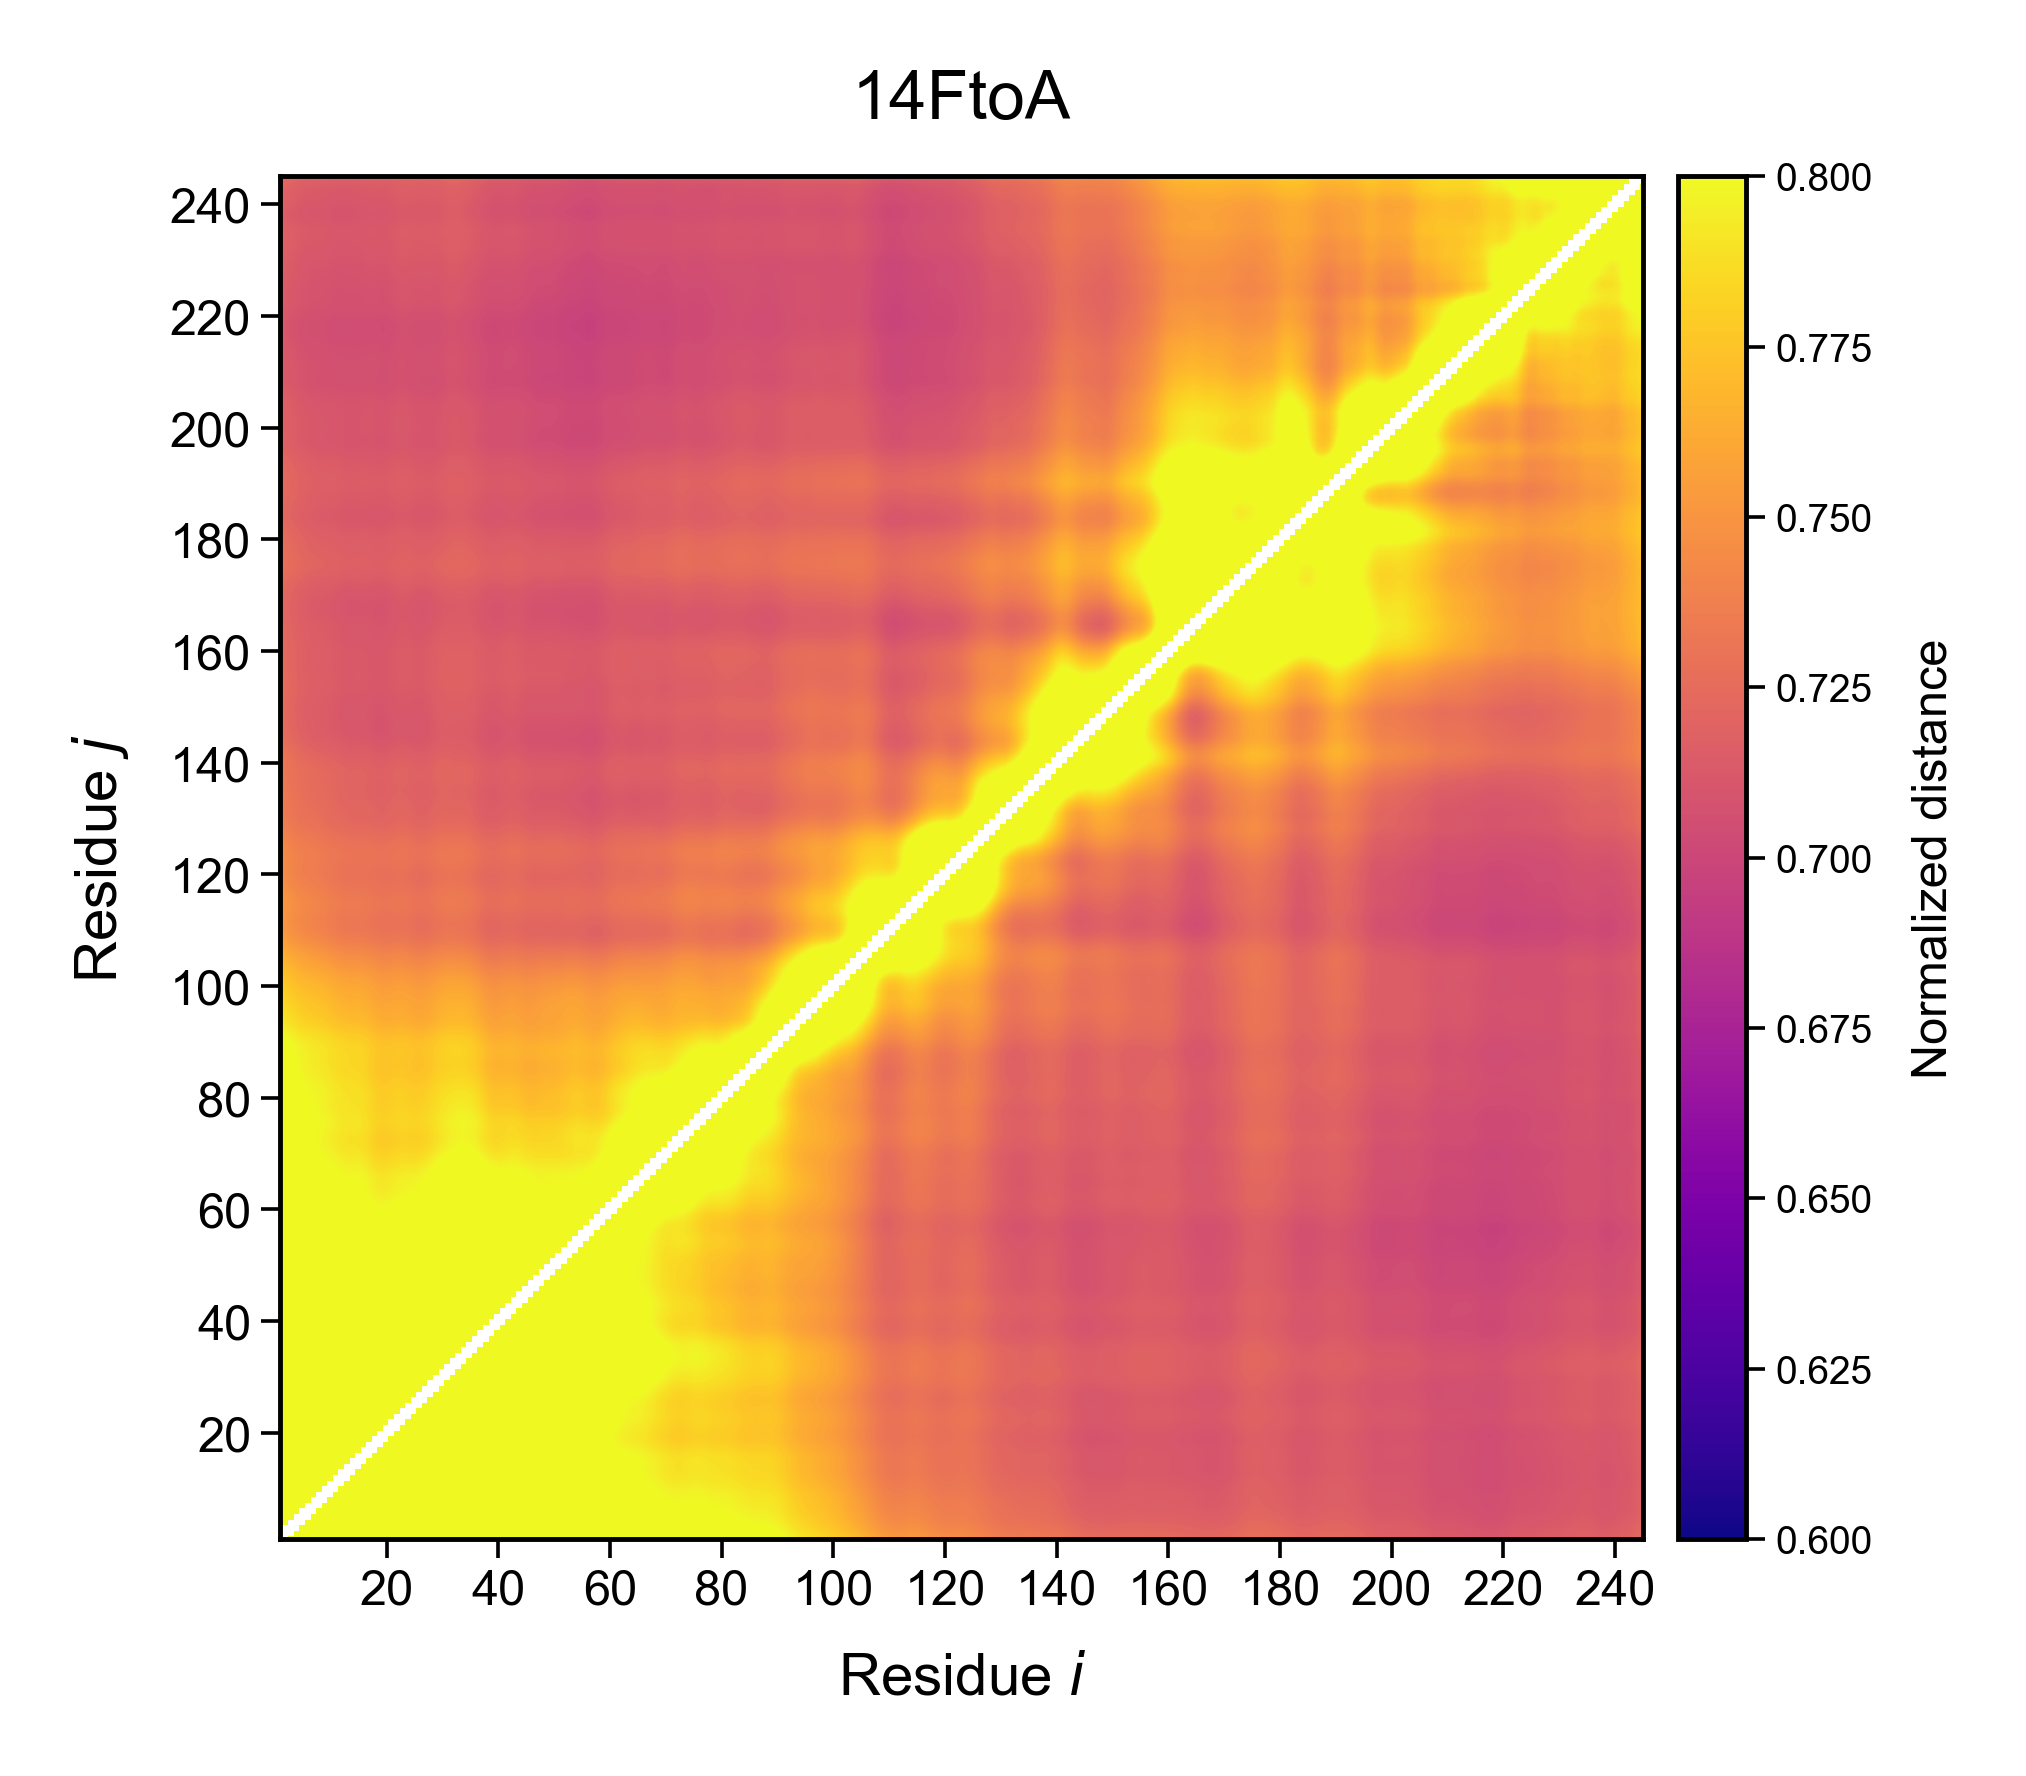

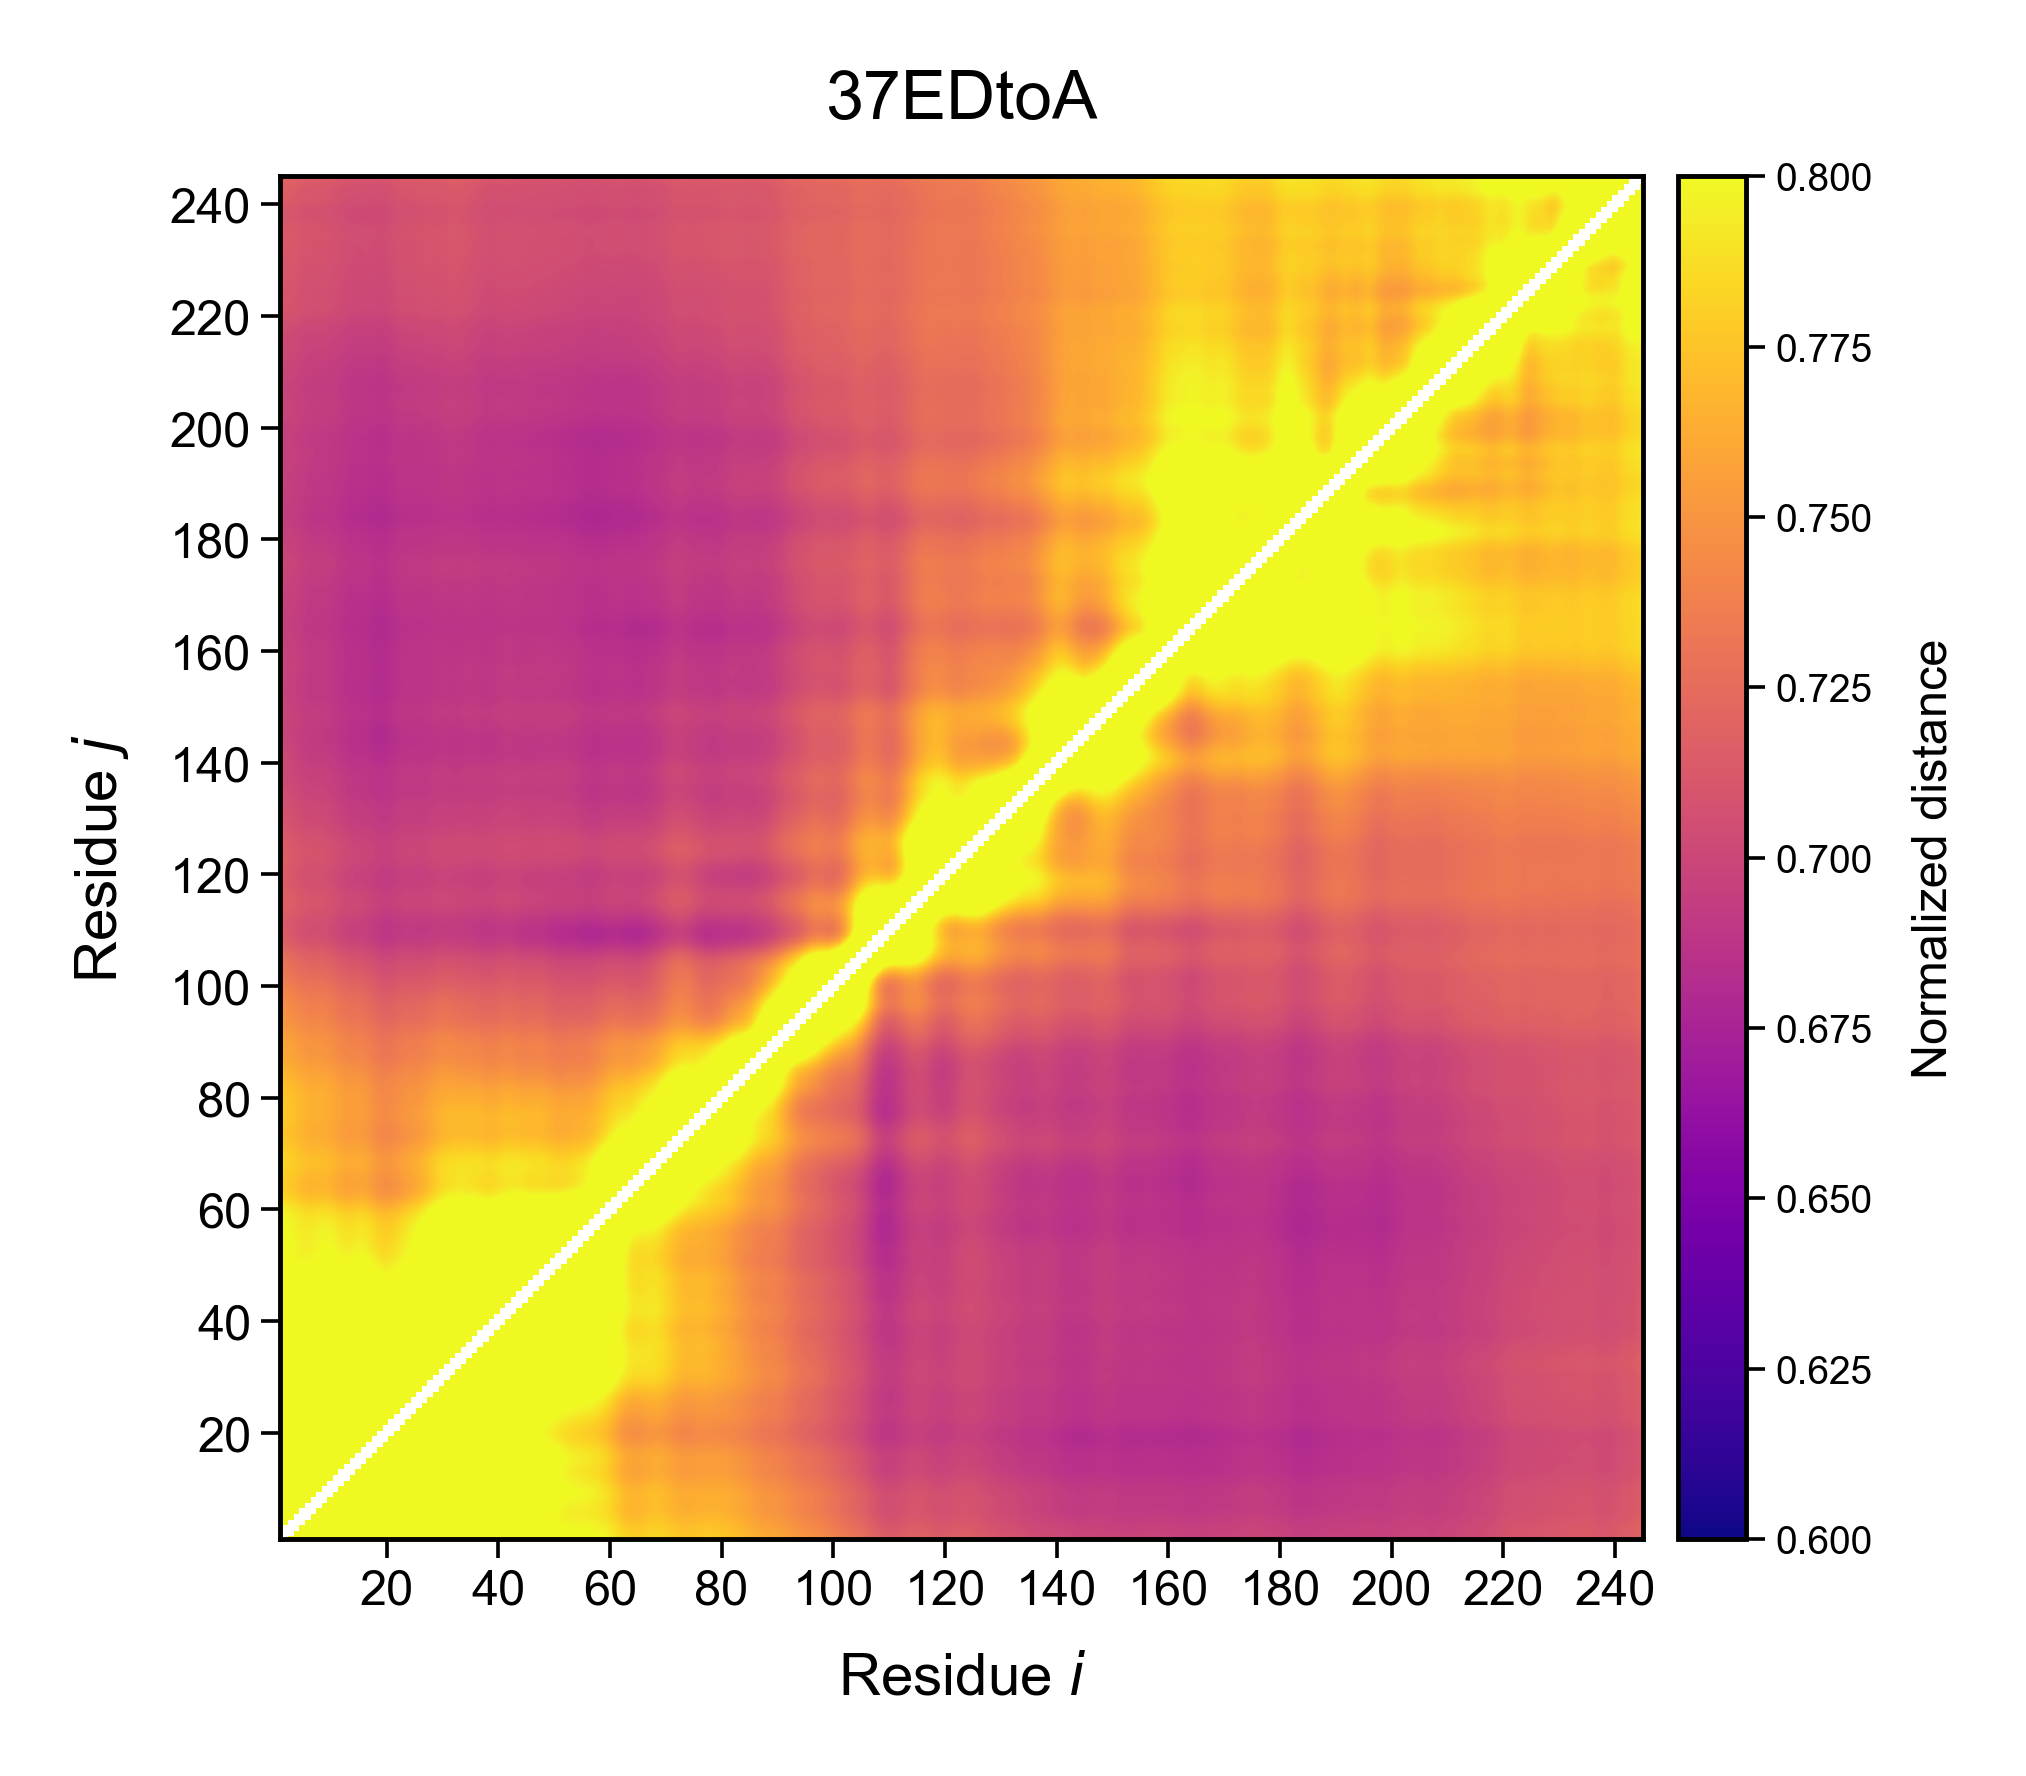

In [5]:
scaling_maps = {}

for letter, title, seq_file, ref_file, short in PANELS:
    scaling_maps[short] = plot_scaling_map(
        ensembles[seq_file],
        ensembles[ref_file],
        title=title,
        outfile=f'figures/figure_S6{letter}_scaling_map_{short}',
    )

## Quantifying the loss of long-range contacts

The panels make the effect obvious by eye, but it is worth stating numerically. For each sequence we take the mean normalised distance over well-separated residue pairs (more than 20 apart in sequence), ignoring the undefined diagonal. A larger value means a more expanded chain with fewer long-range contacts.

In [6]:
def mean_long_range(scaling_map, min_separation=20):
    """
    Mean normalised distance over residue pairs separated in sequence.

    Parameters
    ----------
    scaling_map : numpy.ndarray
        A square scaling map, possibly containing nan on the diagonal.

    min_separation : int
        Only pairs at least this far apart in sequence are included.
        Default = 20.

    Returns
    -------
    float
        The mean normalised distance over the selected pairs.
    """

    n = scaling_map.shape[0]
    i, j = np.indices((n, n))
    mask = (np.abs(i - j) >= min_separation) & np.isfinite(scaling_map)

    return float(np.mean(scaling_map[mask]))


print(f'{"sequence":<22}{"mean normalised distance (|i-j| > 20)"}')
for _, title, seq_file, _, short in PANELS:
    print(f'{title:<22}{mean_long_range(scaling_maps[short]):.4f}')

sequence              mean normalised distance (|i-j| > 20)
DDX4 NTD (wildtype)   0.6659
24RtoK                0.7567
14FtoA                0.7341
37EDtoA               0.7233


## Differences from the published figure

* **Assembly and labelling.** The published Figure S6 was assembled in a vector graphics editor from the four panel exports; the A-D letters were added there.
* **Panel titles.** The titles are drawn by the notebook so each panel is self-identifying when viewed on its own. The published layout labels them the same way.
* **The null model.** The original notebook created an `AnalyticalFRC` object for DDX4 and then did not use it - the normalisation is against the SP-repeat STARLING ensemble in both the original and here. The unused analytical reference has been dropped.
* **Explicit shape check.** Pairing a variant with a mismatched-length null model would broadcast or fail obscurely, so the function now raises a clear error. This matters most for 24RtoK, which is 236 residues rather than 245.
* **Divide-by-zero handling.** The original emitted a `RuntimeWarning` on the undefined diagonal; the behaviour is unchanged but the division is now explicitly wrapped so the intent is clear rather than looking like an accident.
* **Deprecated colormap call.** `matplotlib.cm.get_cmap` was removed in Matplotlib 3.11; this uses `matplotlib.colormaps[...]` instead. The colormap itself (`plasma`) is unchanged.